# BeamBudget-LiDAR
How much depth information survives when a LiDAR loses beams? KITTI raw `2011_09_26_drive_0005`, Velodyne HDL-64E → simulated 32/16/8 beams by ring removal, image-plane interpolation, held-out evaluation.

See `README.md` for results and limitations.

## 1. Data

In [ ]:
!mkdir -p /content/kitti && cd /content/kitti && \
 wget -q https://s3.eu-central-1.amazonaws.com/avg-kitti/raw_data/2011_09_26_calib.zip && \
 wget -q https://s3.eu-central-1.amazonaws.com/avg-kitti/raw_data/2011_09_26_drive_0005/2011_09_26_drive_0005_sync.zip && \
 unzip -q 2011_09_26_calib.zip && unzip -q 2011_09_26_drive_0005_sync.zip
!ls /content/kitti/2011_09_26

2011_09_26_drive_0005_sync  calib_imu_to_velo.txt
calib_cam_to_cam.txt	    calib_velo_to_cam.txt


In [ ]:
import numpy as np, glob, time
import matplotlib.pyplot as plt
from PIL import Image

ROOT  = "/content/kitti/2011_09_26"
DRIVE = f"{ROOT}/2011_09_26_drive_0005_sync"
scans = sorted(glob.glob(f"{DRIVE}/velodyne_points/data/*.bin"))
imgs  = sorted(glob.glob(f"{DRIVE}/image_02/data/*.png"))
print(len(scans), "scans,", len(imgs), "images")

pts = np.fromfile(scans[0], dtype=np.float32).reshape(-1, 4)  # x, y, z, reflectance
print("points in scan 0:", pts.shape)
print(pts[:3])

154 scans, 154 images
points in scan 0: (123397, 4)
[[22.719  0.031  0.977  0.32 ]
 [18.052  0.076  0.82   0.46 ]
 [18.026  0.132  0.819  0.24 ]]


## 2. Calibration and projection
`P_rect_02 · R_rect_00 · T_velo→cam`, followed by sanity checks.

In [ ]:
!grep -E "S_rect_02|R_rect_00|P_rect_02" /content/kitti/2011_09_26/calib_cam_to_cam.txt
!cat /content/kitti/2011_09_26/calib_velo_to_cam.txt

R_rect_00: 9.999239e-01 9.837760e-03 -7.445048e-03 -9.869795e-03 9.999421e-01 -4.278459e-03 7.402527e-03 4.351614e-03 9.999631e-01
S_rect_02: 1.242000e+03 3.750000e+02
P_rect_02: 7.215377e+02 0.000000e+00 6.095593e+02 4.485728e+01 0.000000e+00 7.215377e+02 1.728540e+02 2.163791e-01 0.000000e+00 0.000000e+00 1.000000e+00 2.745884e-03
calib_time: 15-Mar-2012 11:37:16
R: 7.533745e-03 -9.999714e-01 -6.166020e-04 1.480249e-02 7.280733e-04 -9.998902e-01 9.998621e-01 7.523790e-03 1.480755e-02
T: -4.069766e-03 -7.631618e-02 -2.717806e-01
delta_f: 0.000000e+00 0.000000e+00
delta_c: 0.000000e+00 0.000000e+00


In [ ]:
def read_calib_file(path):
    out = {}
    with open(path) as f:
        for line in f:
            if ':' not in line:
                continue
            k, v = line.split(':', 1)
            try:
                out[k.strip()] = np.array([float(x) for x in v.split()])
            except ValueError:
                pass                      # skips calib_time (not numeric)
    return out

def load_kitti_calib(calib_dir, cam=2):
    c2c = read_calib_file(f"{calib_dir}/calib_cam_to_cam.txt")
    v2c = read_calib_file(f"{calib_dir}/calib_velo_to_cam.txt")
    P = c2c[f"P_rect_0{cam}"].reshape(3, 4)
    R_rect = np.eye(4)
    R_rect[:3, :3] = c2c["R_rect_00"].reshape(3, 3)
    Tr = np.eye(4)
    Tr[:3, :3] = v2c["R"].reshape(3, 3)
    Tr[:3, 3] = v2c["T"]
    w, h = c2c[f"S_rect_0{cam}"].astype(int)
    return P, R_rect, Tr, (w, h)

P, R_rect, Tr, IMG_SIZE = load_kitti_calib(ROOT)
fx, fy, cx, cy = P[0, 0], P[1, 1], P[0, 2], P[1, 2]
print(f"fx={fx:.2f}  fy={fy:.2f}  cx={cx:.2f}  cy={cy:.2f}  size={IMG_SIZE}")
print("P_rect_02 =\n", np.round(P, 4))

fx=721.54  fy=721.54  cx=609.56  cy=172.85  size=(np.int64(1242), np.int64(375))
P_rect_02 =
 [[7.215377e+02 0.000000e+00 6.095593e+02 4.485730e+01]
 [0.000000e+00 7.215377e+02 1.728540e+02 2.164000e-01]
 [0.000000e+00 0.000000e+00 1.000000e+00 2.700000e-03]]


In [ ]:
R = Tr[:3, :3]
w, h = IMG_SIZE
checks = {
    "fx == fy (rectified)":       abs(fx - fy) < 1e-6,
    "cx, cy inside image":        0 < cx < w and 0 < cy < h,
    "R orthonormal":              np.allclose(R @ R.T, np.eye(3), atol=1e-4),
    "det(R) = +1 (no mirror)":    abs(np.linalg.det(R) - 1) < 1e-4,
    "LiDAR x-fwd -> cam z-fwd":   (R @ [1, 0, 0])[2] > 0.99,
}
for k, ok in checks.items():
    print("OK  " if ok else "FAIL", k)

OK   fx == fy (rectified)
OK   cx, cy inside image
OK   R orthonormal
OK   det(R) = +1 (no mirror)
OK   LiDAR x-fwd -> cam z-fwd


20478 / 123397 points in image (16.6%)
depth range: 4.93 – 68.26 m


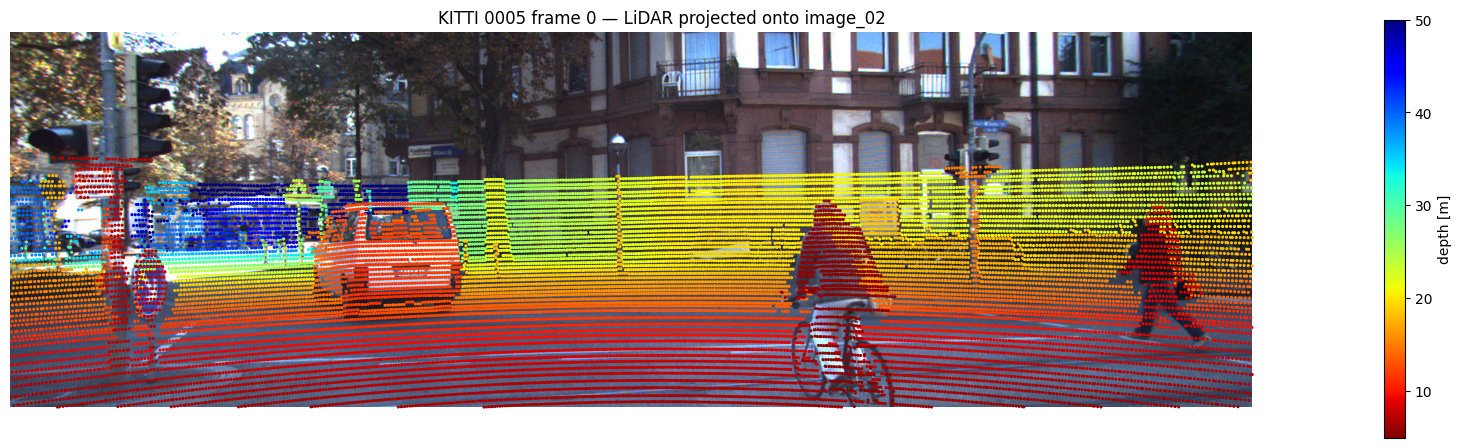

In [ ]:
def project_velo_to_image(pts_velo, P, R_rect, Tr, img_size, min_depth=0.5):
    n = len(pts_velo)
    X = np.hstack([pts_velo[:, :3], np.ones((n, 1))]).T   # 4xN homogeneous
    Y = P @ R_rect @ Tr @ X                               # 3xN
    z = Y[2]
    w, h = img_size
    front = z > min_depth                                 # drop points behind camera
    u = np.full(n, -1.0); v = np.full(n, -1.0)
    u[front] = Y[0, front] / z[front]
    v[front] = Y[1, front] / z[front]
    inside = front & (u >= 0) & (u < w) & (v >= 0) & (v < h)
    idx = np.nonzero(inside)[0]
    return u[idx], v[idx], z[idx], idx

u, v, z, idx = project_velo_to_image(pts, P, R_rect, Tr, IMG_SIZE)
print(f"{len(idx)} / {len(pts)} points in image ({100*len(idx)/len(pts):.1f}%)")
print(f"depth range: {z.min():.2f} – {z.max():.2f} m")

img = np.array(Image.open(imgs[0]))
plt.figure(figsize=(18, 6))
plt.imshow(img)
plt.scatter(u, v, c=z, s=1.5, cmap="jet_r", vmax=50)
plt.colorbar(label="depth [m]", fraction=0.015)
plt.title("KITTI 0005 frame 0 — LiDAR projected onto image_02")
plt.axis("off"); plt.show()

## 3. Ring recovery
The `.bin` files carry no ring index. The first attempt below splits at ±180° and falls back to elevation quantiles; the diagnostics that follow show why that is wrong and how the sweep cut angle fixes it.

scan-order gave 65 rings -> using elevation fallback
rings found: 64
elevation top -> bottom: 2.7° ... -23.6°
monotonic: True


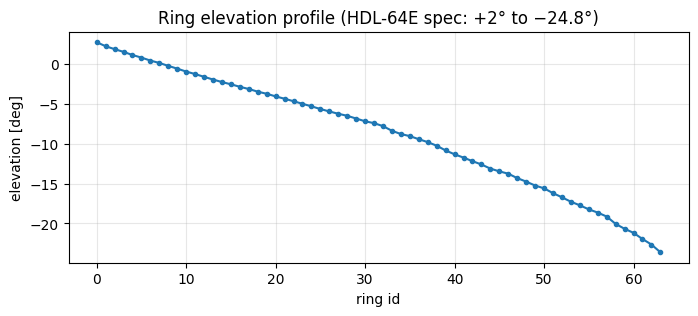

In [ ]:
def assign_rings(pts_velo, expected=64):
    az = np.arctan2(pts_velo[:, 1], pts_velo[:, 0])          # azimuth per point
    jumps = np.abs(np.diff(az)) > np.pi                       # 360° wrap = new laser
    ring = np.concatenate([[0], np.cumsum(jumps)])
    n = ring.max() + 1
    if n != expected:                                          # fallback: elevation quantiles
        print(f"scan-order gave {n} rings -> using elevation fallback")
        el = np.arctan2(pts_velo[:, 2], np.linalg.norm(pts_velo[:, :2], axis=1))
        edges = np.quantile(el, np.linspace(0, 1, expected + 1))
        ring = expected - 1 - np.clip(np.searchsorted(edges, el, side="right") - 1, 0, expected - 1)
    return ring

ring = assign_rings(pts)
print("rings found:", ring.max() + 1)

# verification: median elevation per ring must fall steadily from top laser to bottom
el = np.degrees(np.arctan2(pts[:, 2], np.linalg.norm(pts[:, :2], axis=1)))
prof = np.array([np.median(el[ring == r]) for r in range(ring.max() + 1)])
print("elevation top -> bottom: %.1f° ... %.1f°" % (prof[0], prof[-1]))
print("monotonic:", np.all(np.diff(prof) < 0))

plt.figure(figsize=(8, 3))
plt.plot(prof, "o-", ms=3); plt.xlabel("ring id"); plt.ylabel("elevation [deg]")
plt.title("Ring elevation profile (HDL-64E spec: +2° to −24.8°)"); plt.grid(alpha=.3); plt.show()

positive jumps (-180 -> +180): 0
negative jumps (+180 -> -180): 64
segments: 65 | median length: 2025
first / last segment length: 995 / 538
5 shortest (length, id): [(np.int64(538), 64), (np.int64(995), 0), (np.int64(1156), 63), (np.int64(1230), 62), (np.int64(1252), 61)]
max within-segment elevation std: 0.71°


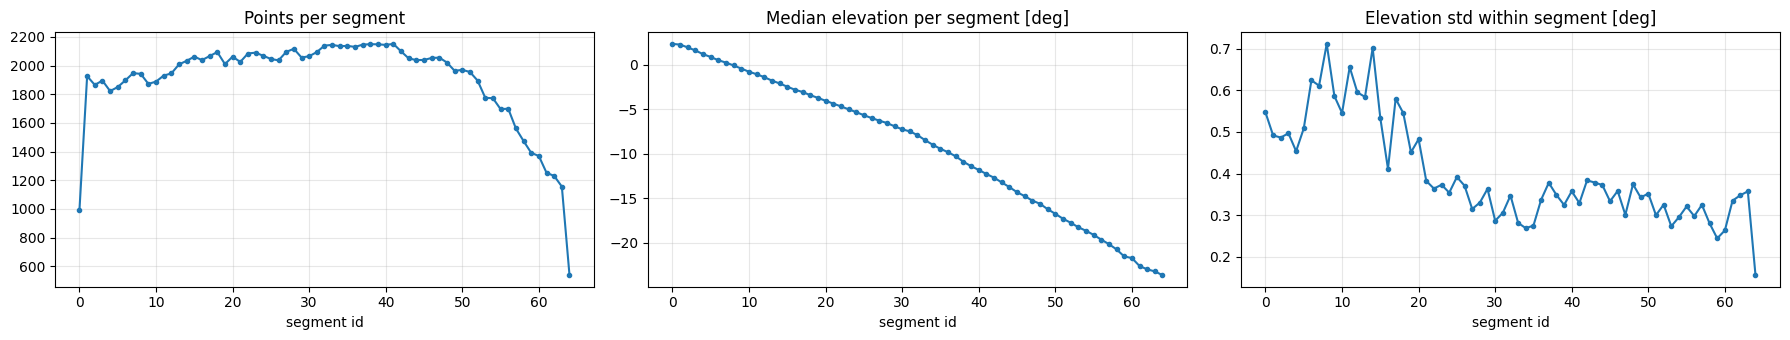

In [ ]:
az = np.arctan2(pts[:, 1], pts[:, 0])
el = np.degrees(np.arctan2(pts[:, 2], np.linalg.norm(pts[:, :2], axis=1)))
d = np.diff(az)

print("positive jumps (-180 -> +180):", (d >  np.pi).sum())
print("negative jumps (+180 -> -180):", (d < -np.pi).sum())

boundaries = np.where(np.abs(d) > np.pi)[0]
starts = np.r_[0, boundaries + 1]
ends   = np.r_[boundaries + 1, len(pts)]
lengths = ends - starts
el_med = np.array([np.median(el[s:e]) for s, e in zip(starts, ends)])
el_std = np.array([np.std(el[s:e])    for s, e in zip(starts, ends)])

print("segments:", len(lengths), "| median length:", int(np.median(lengths)))
print("first / last segment length:", lengths[0], "/", lengths[-1])
print("5 shortest (length, id):", sorted(zip(lengths, range(len(lengths))))[:5])
print("max within-segment elevation std: %.2f°" % el_std.max())

fig, ax = plt.subplots(1, 3, figsize=(18, 3.5))
ax[0].plot(lengths, ".-");  ax[0].set(title="Points per segment", xlabel="segment id")
ax[1].plot(el_med, ".-");   ax[1].set(title="Median elevation per segment [deg]", xlabel="segment id")
ax[2].plot(el_std, ".-");   ax[2].set(title="Elevation std within segment [deg]", xlabel="segment id")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

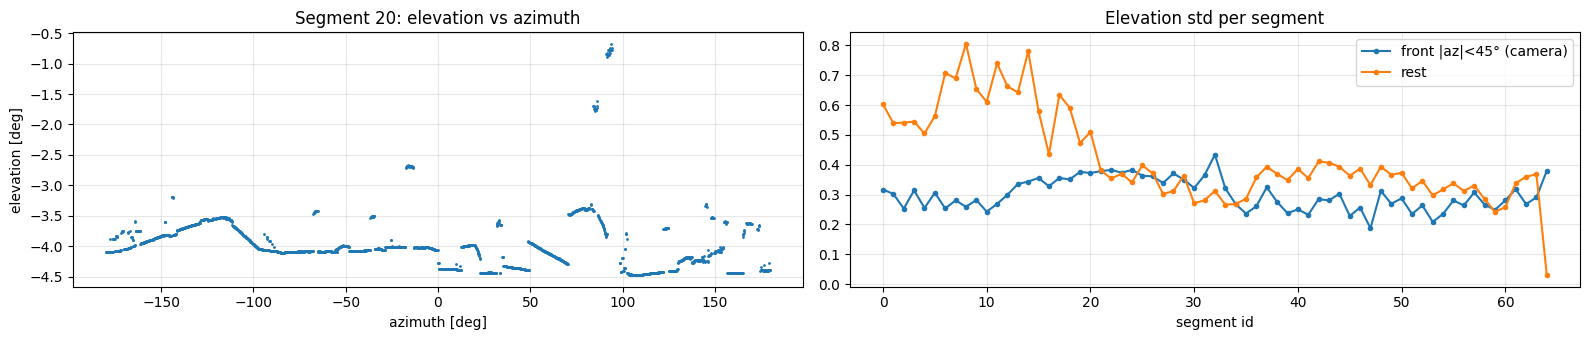

median std front: 0.291°   rest: 0.370°


In [ ]:
seg = np.repeat(np.arange(len(lengths)), lengths)        # segment id per point

# 1) look inside one segment: does elevation step at some azimuth?
s, e = starts[20], ends[20]
fig, ax = plt.subplots(1, 2, figsize=(16, 3.5))
ax[0].plot(np.degrees(az[s:e]), el[s:e], ".", ms=2)
ax[0].set(title="Segment 20: elevation vs azimuth", xlabel="azimuth [deg]", ylabel="elevation [deg]")

# 2) elevation spread per segment: front (camera view) vs rear
front = np.abs(np.degrees(az)) < 45
std_front = [np.std(el[(seg == k) & front]) for k in range(len(lengths))]
std_rear  = [np.std(el[(seg == k) & ~front]) for k in range(len(lengths))]
ax[1].plot(std_front, ".-", label="front |az|<45° (camera)")
ax[1].plot(std_rear,  ".-", label="rest")
ax[1].set(title="Elevation std per segment", xlabel="segment id"); ax[1].legend()
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()
print("median std front: %.3f°   rest: %.3f°" % (np.median(std_front), np.median(std_rear)))

first point azimuth: 0.1°   last point azimuth: -13.9°
ring ids: 0 to 63 | count: 64
median std  segments:  front 0.291°  all 0.358°
median std  true rings: front 0.168°  all 0.314°
monotonic: True


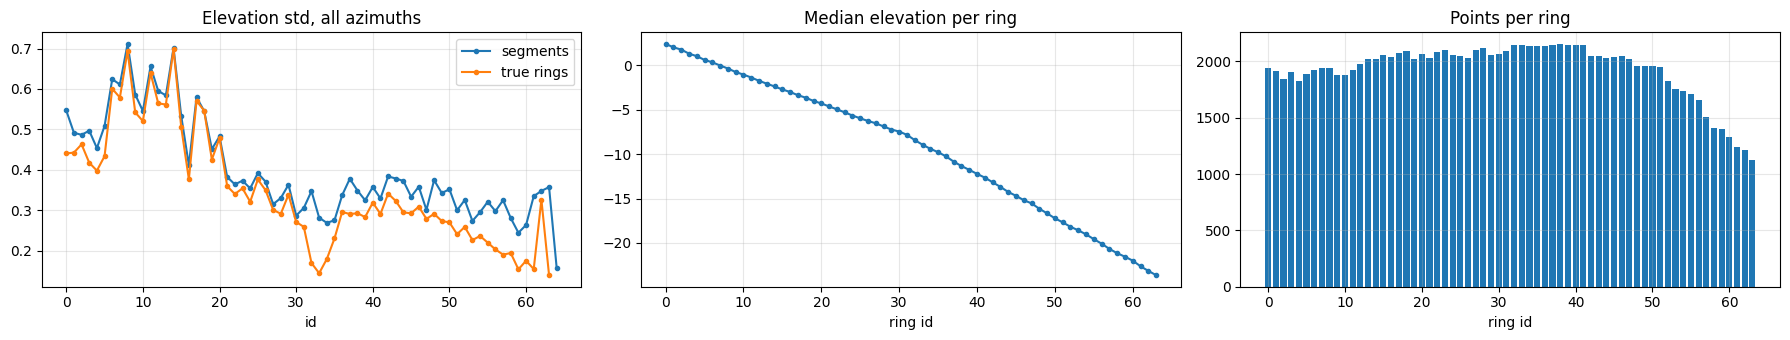

In [ ]:
a_first = np.degrees(az[0])
a_last  = np.degrees(az[-1])
print(f"first point azimuth: {a_first:.1f}°   last point azimuth: {a_last:.1f}°")

a0 = np.radians(a_first)
ring_true = seg - (az < a0).astype(int)
print("ring ids:", ring_true.min(), "to", ring_true.max(), "| count:", len(np.unique(ring_true)))

def ring_stats(r):
    ids = np.unique(r)
    std_f = np.array([np.std(el[(r == k) & front]) for k in ids])
    std_a = np.array([np.std(el[r == k]) for k in ids])
    prof  = np.array([np.median(el[r == k]) for k in ids])
    return std_f, std_a, prof

sf_old, sa_old, _    = ring_stats(seg)
sf_new, sa_new, prof = ring_stats(ring_true)
print("median std  segments:  front %.3f°  all %.3f°" % (np.median(sf_old), np.median(sa_old)))
print("median std  true rings: front %.3f°  all %.3f°" % (np.median(sf_new), np.median(sa_new)))
print("monotonic:", np.all(np.diff(prof) < 0))

fig, ax = plt.subplots(1, 3, figsize=(18, 3.5))
ax[0].plot(sa_old, ".-", label="segments"); ax[0].plot(sa_new, ".-", label="true rings")
ax[0].set(title="Elevation std, all azimuths", xlabel="id"); ax[0].legend()
ax[1].plot(prof, ".-"); ax[1].set(title="Median elevation per ring", xlabel="ring id")
ax[2].bar(range(len(prof)), np.bincount(ring_true)); ax[2].set(title="Points per ring", xlabel="ring id")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Ring recovery finding:** KITTI raw sweeps start/end facing forward (az≈0°, camera trigger),
not at ±180°. Naive azimuth-wrap splitting gives 65 segments, each mixing two lasers inside the
camera FOV. Correcting with the cut angle gives 64 rings; front elevation std drops 0.29°→0.17°.

*First version of the corrected function, tested on 4 frames. The assertion error on frame 153 is kept on purpose: it led to the truncated-sweep finding below.*

In [ ]:
def assign_rings(pts_velo, expected=64):
    az = np.arctan2(pts_velo[:, 1], pts_velo[:, 0])
    seg = np.concatenate([[0], np.cumsum(np.diff(az) < -np.pi)])   # +180 -> -180 wraps
    a0 = az[0]                                                     # sweep cut angle (~0° in KITTI)
    ring = np.clip(seg - (az < a0).astype(int), 0, None)
    n = len(np.unique(ring))
    assert n == expected, f"got {n} rings"
    return ring

for i in [0, 50, 100, 153]:
    p = np.fromfile(scans[i], dtype=np.float32).reshape(-1, 4)
    r = assign_rings(p)
    print(f"frame {i:3d}: cut az {np.degrees(np.arctan2(p[0,1], p[0,0])):5.1f}°  rings {r.max()+1}")

ring = assign_rings(pts)   # frame 0, used below

frame   0: cut az   0.1°  rings 64
frame  50: cut az   0.1°  rings 64
frame 100: cut az   0.2°  rings 64


AssertionError: got 53 rings

In [ ]:
for i in [0, 153]:
    p = np.fromfile(scans[i], dtype=np.float32).reshape(-1, 4)
    d = np.degrees(np.diff(np.arctan2(p[:, 1], p[:, 0])))
    print(f"frame {i}:")
    for thr in [180, 150, 120, 90, 60, 30, 10, 5, 2]:
        print(f"   wraps with drop > {thr:3d}°: {(d < -thr).sum()}")
    neg = d[d < -2]
    print("   backward steps between 2° and 180° :", np.sort(neg[neg > -180]).round(1)[:20])

frame 0:
   wraps with drop > 180°: 64
   wraps with drop > 150°: 64
   wraps with drop > 120°: 64
   wraps with drop >  90°: 64
   wraps with drop >  60°: 64
   wraps with drop >  30°: 64
   wraps with drop >  10°: 64
   wraps with drop >   5°: 64
   wraps with drop >   2°: 64
   backward steps between 2° and 180° : []
frame 153:
   wraps with drop > 180°: 52
   wraps with drop > 150°: 52
   wraps with drop > 120°: 52
   wraps with drop >  90°: 52
   wraps with drop >  60°: 52
   wraps with drop >  30°: 52
   wraps with drop >  10°: 52
   wraps with drop >   5°: 52
   wraps with drop >   2°: 52
   backward steps between 2° and 180° : []


frames with 64 rings: 153 / 154
bad frames: [153] -> [53]
frame 153 points: 98532 | frame 0 points: 123397


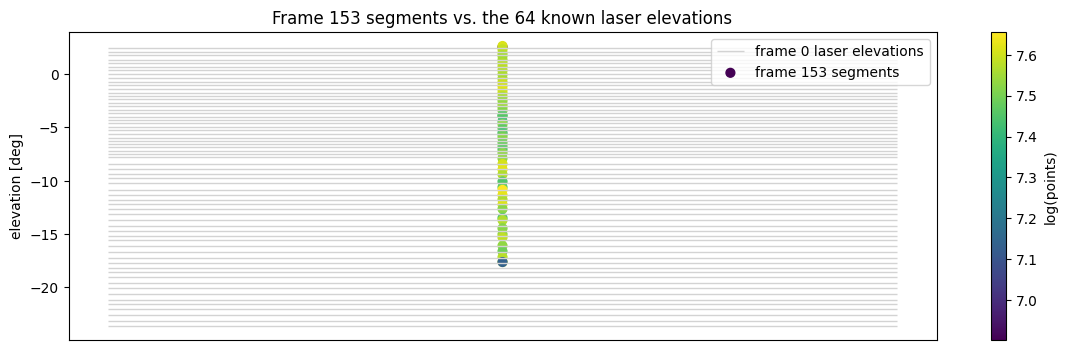

In [ ]:
# reference: the 64 laser elevations learned from frame 0 (validated rings)
ref_el = prof.copy()                     # from Cell 7e, 64 values, top -> bottom

def segments(p):
    a = np.arctan2(p[:, 1], p[:, 0])
    e = np.degrees(np.arctan2(p[:, 2], np.linalg.norm(p[:, :2], axis=1)))
    s = np.concatenate([[0], np.cumsum(np.diff(a) < -np.pi)])
    return a, e, s

# 1) how many of the 154 frames give exactly 64 rings?
n_rings = []
for f in scans:
    p = np.fromfile(f, dtype=np.float32).reshape(-1, 4)
    a, e, s = segments(p)
    n_rings.append(len(np.unique(np.clip(s - (a < a[0]), 0, None))))
n_rings = np.array(n_rings)
print("frames with 64 rings:", (n_rings == 64).sum(), "/", len(n_rings))
print("bad frames:", np.nonzero(n_rings != 64)[0], "->", n_rings[n_rings != 64])

# 2) frame 153: which lasers are present?
p153 = np.fromfile(scans[153], dtype=np.float32).reshape(-1, 4)
a, e, s = segments(p153)
seg_el = np.array([np.median(e[s == k]) for k in np.unique(s)])
seg_n  = np.bincount(s)
print("frame 153 points:", len(p153), "| frame 0 points:", len(pts))

plt.figure(figsize=(14, 4))
plt.hlines(ref_el, 0, 1, colors="lightgray", lw=1, label="frame 0 laser elevations")
plt.scatter(np.full(len(seg_el), 0.5), seg_el, c=np.log(seg_n), cmap="viridis", s=40, label="frame 153 segments")
plt.ylabel("elevation [deg]"); plt.xticks([]); plt.legend(); plt.colorbar(label="log(points)")
plt.title("Frame 153 segments vs. the 64 known laser elevations"); plt.show()

**Frame exclusion:** frame 153 (last of drive 0005) is a truncated sweep — 98.5k points,
only 53 lasers (bottom 11 missing). Excluded. Ring recovery validated on 153/154 frames.

In [ ]:
def assign_rings(pts_velo, expected=64):
    az = np.arctan2(pts_velo[:, 1], pts_velo[:, 0])
    seg = np.concatenate([[0], np.cumsum(np.diff(az) < -np.pi)])   # +180 -> -180 wraps
    ring = np.clip(seg - (az < az[0]).astype(int), 0, None)         # sweep cut at az[0] (~0°)
    n = len(np.unique(ring))
    assert n == expected, f"got {n} rings (truncated sweep?)"
    return ring

VALID_FRAMES = [i for i in range(len(scans)) if n_rings[i] == 64]
print(len(VALID_FRAMES), "valid frames")
ring = assign_rings(pts)    # frame 0

153 valid frames


## 4. Beam reduction

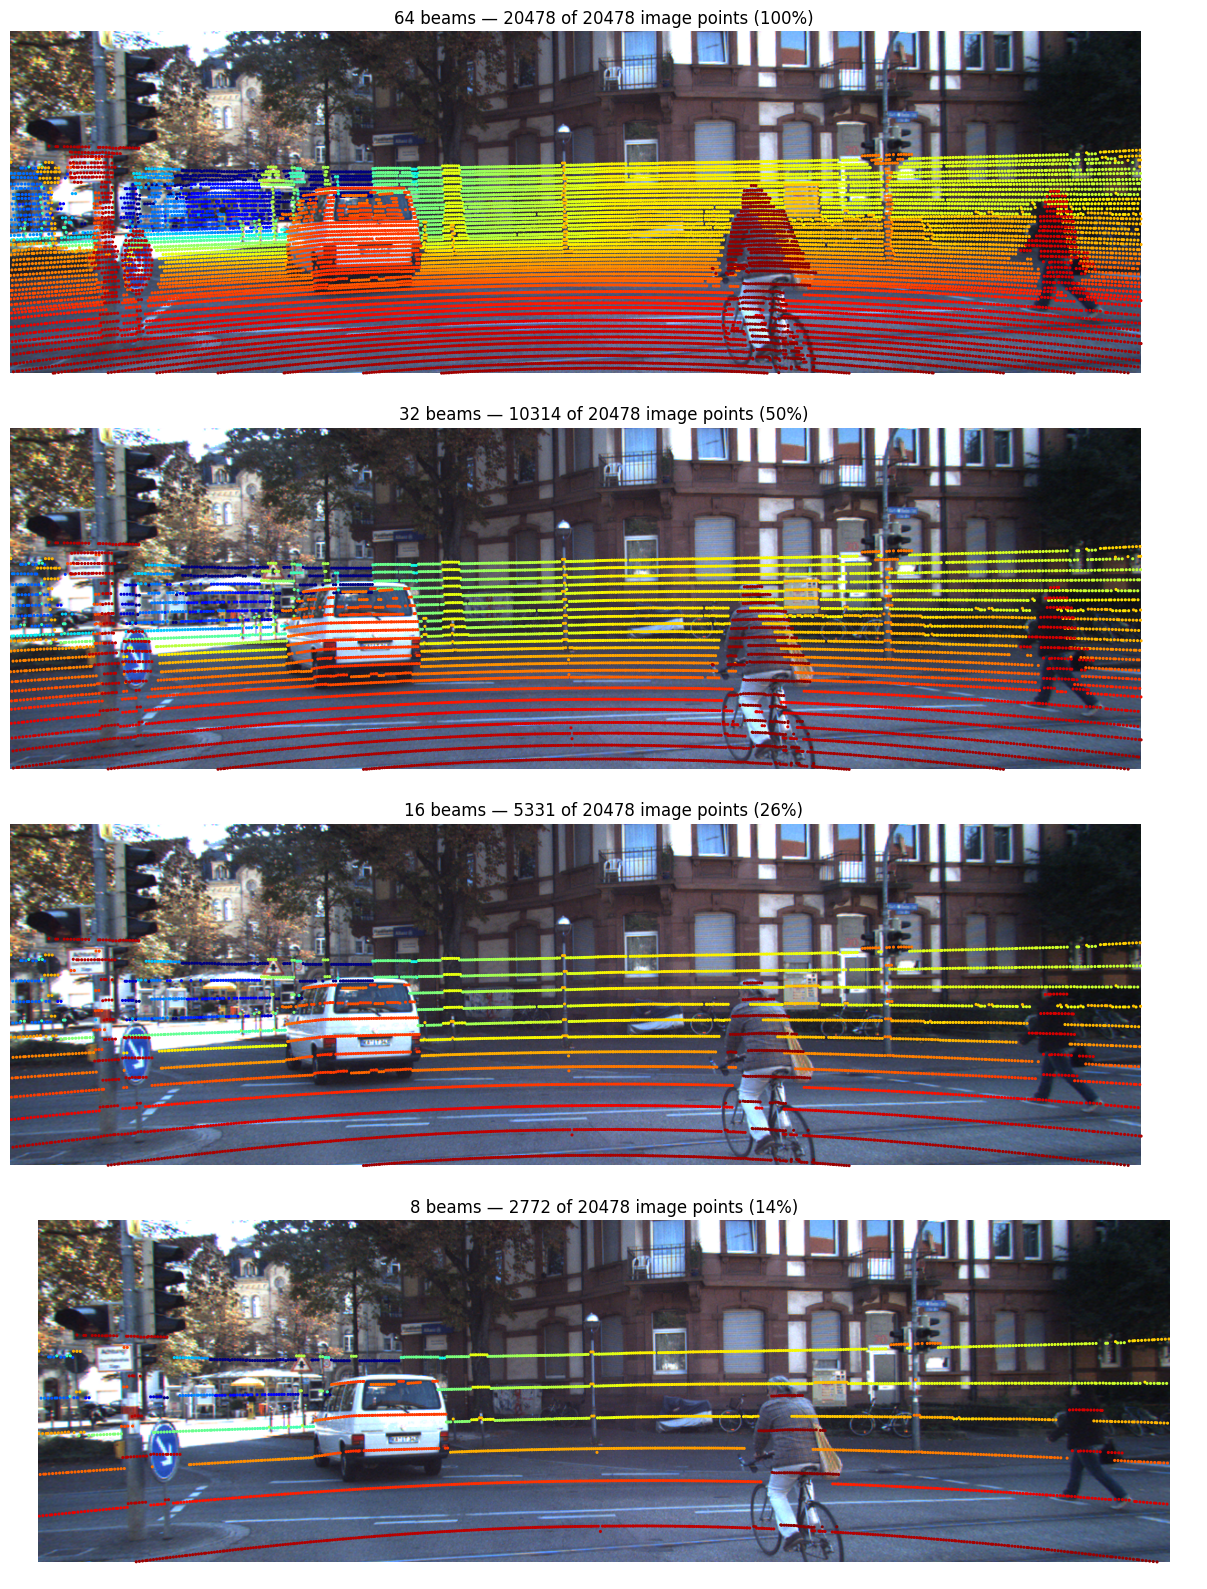

In [ ]:
def reduce_beams(ring, n_keep, n_total=64):
    kept = np.arange(0, n_total, n_total // n_keep)
    return np.isin(ring, kept)

ring_img = ring[idx]                       # ring id of each image-visible point
fig, axes = plt.subplots(4, 1, figsize=(16, 16))
for ax, nk in zip(axes, [64, 32, 16, 8]):
    keep = reduce_beams(ring_img, nk)
    ax.imshow(img)
    ax.scatter(u[keep], v[keep], c=z[keep], s=1.5, cmap="jet_r", vmax=50)
    ax.set_title(f"{nk} beams — {keep.sum()} of {len(keep)} image points ({100*keep.mean():.0f}%)")
    ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Interpolation baselines and metrics (frame 0)
Held-out evaluation: kept rings are input, dropped rings are ground truth.

In [ ]:
from scipy.interpolate import griddata
import pandas as pd

def interpolate_depth(u_k, v_k, z_k, u_q, v_q, method):
    pts_k, q = np.column_stack([u_k, v_k]), np.column_stack([u_q, v_q])
    if method == "nearest":    return griddata(pts_k, z_k, q, method="nearest")
    if method == "linear":     return griddata(pts_k, z_k, q, method="linear")
    if method == "linear_inv": return 1.0 / griddata(pts_k, 1.0 / z_k, q, method="linear")

def depth_metrics(pred, gt):
    ok = np.isfinite(pred) & (pred > 0)           # linear gives NaN outside the convex hull
    e = pred[ok] - gt[ok]
    return dict(coverage=ok.mean(),
                rmse=np.sqrt(np.mean(e**2)),
                mae=np.mean(np.abs(e)),
                match_10cm=np.mean(np.abs(e) <= 0.10),
                delta_105=np.mean(np.maximum(pred[ok]/gt[ok], gt[ok]/pred[ok]) < 1.05))

rows = []
for nk in [32, 16, 8]:
    keep = reduce_beams(ring_img, nk)
    for m in ["nearest", "linear", "linear_inv"]:
        t0 = time.perf_counter()
        pred = interpolate_depth(u[keep], v[keep], z[keep], u[~keep], v[~keep], m)
        ms = 1e3 * (time.perf_counter() - t0)
        rows.append(dict(beams=nk, method=m, n_input=keep.sum(), n_gt=(~keep).sum(),
                         **depth_metrics(pred, z[~keep]), runtime_ms=ms))

df0 = pd.DataFrame(rows)
df0.round(3)

,beams,method,n_input,n_gt,coverage,rmse,mae,match_10cm,delta_105,runtime_ms
0,32,nearest,10314,10164,1.000,6.156,1.898,0.281,0.733,67.577
1,32,linear,10314,10164,0.999,4.838,1.318,0.645,0.850,2680.363
2,32,linear_inv,10314,10164,0.999,5.014,1.319,0.667,0.849,409.267
3,16,nearest,5331,15147,1.000,6.023,2.019,0.273,0.529,31.070
4,16,linear,5331,15147,0.996,4.977,1.514,0.415,0.793,122.649
5,16,linear_inv,5331,15147,0.996,5.214,1.539,0.532,0.791,96.531
6,8,nearest,2772,17706,1.000,6.492,2.531,0.252,0.437,25.164
7,8,linear,2772,17706,0.991,5.159,1.966,0.259,0.651,48.132
8,8,linear_inv,2772,17706,0.991,5.722,2.030,0.334,0.658,48.307


edge points: 25.8% of image points
all    {'coverage': np.float64(0.996), 'rmse': np.float64(5.214), 'mae': np.float64(1.539), 'medae': np.float64(0.09), 'p90': np.float64(3.489), 'match_10cm': np.float64(0.532), 'delta_105': np.float64(0.791)}
smooth {'coverage': np.float64(0.995), 'rmse': np.float64(1.026), 'mae': np.float64(0.248), 'medae': np.float64(0.06), 'p90': np.float64(0.41), 'match_10cm': np.float64(0.683), 'delta_105': np.float64(0.945)}
edge   {'coverage': np.float64(0.999), 'rmse': np.float64(10.179), 'mae': np.float64(5.316), 'medae': np.float64(2.025), 'p90': np.float64(13.407), 'match_10cm': np.float64(0.092), 'delta_105': np.float64(0.34)}


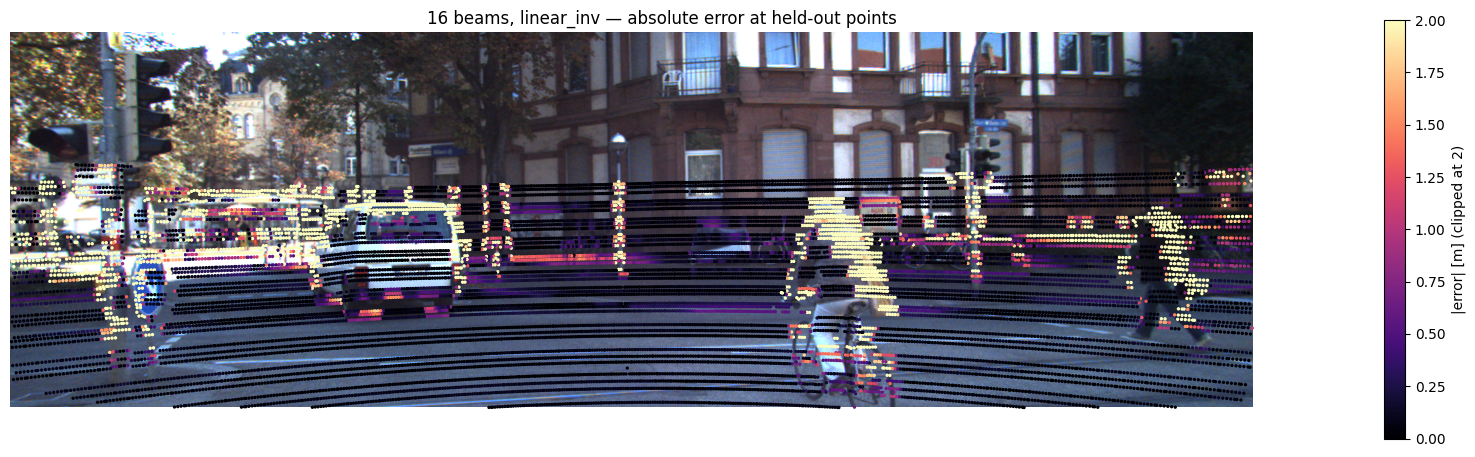

In [ ]:
from scipy.spatial import cKDTree

def depth_metrics(pred, gt):
    ok = np.isfinite(pred) & (pred > 0)
    e = np.abs(pred[ok] - gt[ok])
    return dict(coverage=ok.mean(), rmse=np.sqrt(np.mean(e**2)), mae=e.mean(),
                medae=np.median(e), p90=np.percentile(e, 90),
                match_10cm=np.mean(e <= 0.10),
                delta_105=np.mean(np.maximum(pred[ok]/gt[ok], gt[ok]/pred[ok]) < 1.05))

# edge points = depth jumps > 1 m to a neighbour in the FULL 64-beam projection
tree = cKDTree(np.column_stack([u, v]))
_, nb = tree.query(np.column_stack([u, v]), k=9)
is_edge = np.abs(z[nb] - z[:, None]).max(axis=1) > 1.0
print(f"edge points: {is_edge.mean():.1%} of image points")

keep = reduce_beams(ring_img, 16)
pred = interpolate_depth(u[keep], v[keep], z[keep], u[~keep], v[~keep], "linear_inv")
err = np.abs(pred - z[~keep])
edge_gt = is_edge[~keep]
for name, msk in [("all", np.ones_like(edge_gt)), ("smooth", ~edge_gt), ("edge", edge_gt)]:
    print(f"{name:6s}", {k: round(v, 3) for k, v in depth_metrics(pred[msk], z[~keep][msk]).items()})

plt.figure(figsize=(18, 6)); plt.imshow(img)
plt.scatter(u[~keep], v[~keep], c=err, s=2, cmap="magma", vmin=0, vmax=2)
plt.colorbar(label="|error| [m] (clipped at 2)", fraction=0.015)
plt.title("16 beams, linear_inv — absolute error at held-out points"); plt.axis("off"); plt.show()

## 6. Full benchmark: 153 frames

In [ ]:
griddata(np.random.rand(10, 2), np.random.rand(10), np.random.rand(5, 2), method="linear")  # warm-up (Qhull)

def run_frame(i, beam_list=(32, 16, 8), methods=("nearest", "linear", "linear_inv")):
    p = np.fromfile(scans[i], dtype=np.float32).reshape(-1, 4)
    r = assign_rings(p)
    u_, v_, z_, idx_ = project_velo_to_image(p, P, R_rect, Tr, IMG_SIZE)
    r_img = r[idx_]
    _, nb_ = cKDTree(np.column_stack([u_, v_])).query(np.column_stack([u_, v_]), k=9)
    edge_ = np.abs(z_[nb_] - z_[:, None]).max(axis=1) > 1.0
    out = []
    for nk in beam_list:
        keep = reduce_beams(r_img, nk)
        for m in methods:
            t0 = time.perf_counter()
            pred = interpolate_depth(u_[keep], v_[keep], z_[keep], u_[~keep], v_[~keep], m)
            ms = 1e3 * (time.perf_counter() - t0)
            gt, eg = z_[~keep], edge_[~keep]
            for region, msk in [("all", np.ones_like(eg)), ("smooth", ~eg), ("edge", eg)]:
                out.append(dict(frame=i, beams=nk, method=m, region=region, runtime_ms=ms,
                                **depth_metrics(pred[msk], gt[msk])))
    return out

all_rows, t_start = [], time.time()
for j, i in enumerate(VALID_FRAMES):
    all_rows += run_frame(i)
    if j % 25 == 0:
        print(f"frame {i:3d}  ({j+1}/{len(VALID_FRAMES)})  {time.time()-t_start:.0f}s")

df = pd.DataFrame(all_rows)
df.to_csv("results_all_frames.csv", index=False)
print("done:", df.shape, f"{time.time()-t_start:.0f}s")

frame   0  (1/153)  3s
frame  25  (26/153)  31s
frame  50  (51/153)  58s
frame  75  (76/153)  103s
frame 100  (101/153)  130s
frame 125  (126/153)  156s
frame 150  (151/153)  182s
done: (4131, 12) 183s


In [ ]:
summary = (df.groupby(["region", "beams", "method"])
             [["coverage", "mae", "medae", "p90", "rmse", "match_10cm", "delta_105", "runtime_ms"]]
             .mean().round(3))
pd.set_option("display.width", 200)
summary.loc[["all", "smooth", "edge"]]

coverage    mae  medae     p90   rmse  match_10cm  delta_105  runtime_ms
region beams method                                                                              
all    8     linear         0.988  1.747  0.321   4.645  4.448       0.237      0.677      98.344
             linear_inv     0.988  1.734  0.179   4.643  4.735       0.408      0.693      70.782
             nearest        1.000  2.308  0.758   5.406  5.651       0.244      0.415      27.221
       16    linear         0.995  1.255  0.118   3.119  3.843       0.457      0.801     131.890
             linear_inv     0.995  1.252  0.079   3.039  3.989       0.569      0.798     132.951
             nearest        1.000  1.699  0.449   3.583  4.812       0.278      0.536      25.168
       32    linear         0.998  0.971  0.062   1.931  3.479       0.628      0.860     250.212
             linear_inv     0.998  0.964  0.060   1.918  3.539       0.659      0.860     298.587
             nearest        1.000  1.466  0.295   2.909  4.531       0.283      0.747      20.477
smooth 8     linear         0.985  0.677  0.200   1.267  2.149       0.315      0.838      98.344
             linear_inv     0.985  0.625  0.088   1.284  2.250       0.540      0.839      70.782
             nearest        1.000  1.070  0.561   1.915  2.886       0.277      0.462      27.221
       16    linear         0.994  0.261  0.077   0.338  1.124       0.607      0.946     131.890
             linear_inv     0.994  0.247  0.049   0.331  1.218       0.743      0.946     132.951
             nearest        1.000  0.522  0.328   0.903  1.589       0.321      0.625      25.168
       32    linear         0.998  0.085  0.041   0.141  0.346       0.797      0.989     250.212
             linear_inv     0.998  0.085  0.041   0.133  0.406       0.834      0.989     298.587
             nearest        1.000  0.258  0.237   0.564  0.338       0.335      0.922      20.477
edge   8     linear         0.997  4.328  1.984  11.237  7.497       0.048      0.288      98.344
             linear_inv     0.997  4.413  1.894  11.903  8.008       0.096      0.340      70.782
             nearest        1.000  5.327  2.526  14.241  9.470       0.158      0.298      27.221
       16    linear         0.998  3.646  1.305  10.239  6.887       0.091      0.452     131.890
             linear_inv     0.998  3.667  1.294  10.309  7.126       0.154      0.443     132.951
             nearest        1.000  4.543  1.869  12.768  8.565       0.172      0.320      25.168
       32    linear         0.999  3.104  0.776   9.288  6.422       0.218      0.551     250.212
             linear_inv     0.999  3.079  0.777   8.809  6.520       0.237      0.549     298.587
             nearest        1.000  4.376  1.582  12.485  8.374       0.154      0.325      20.477

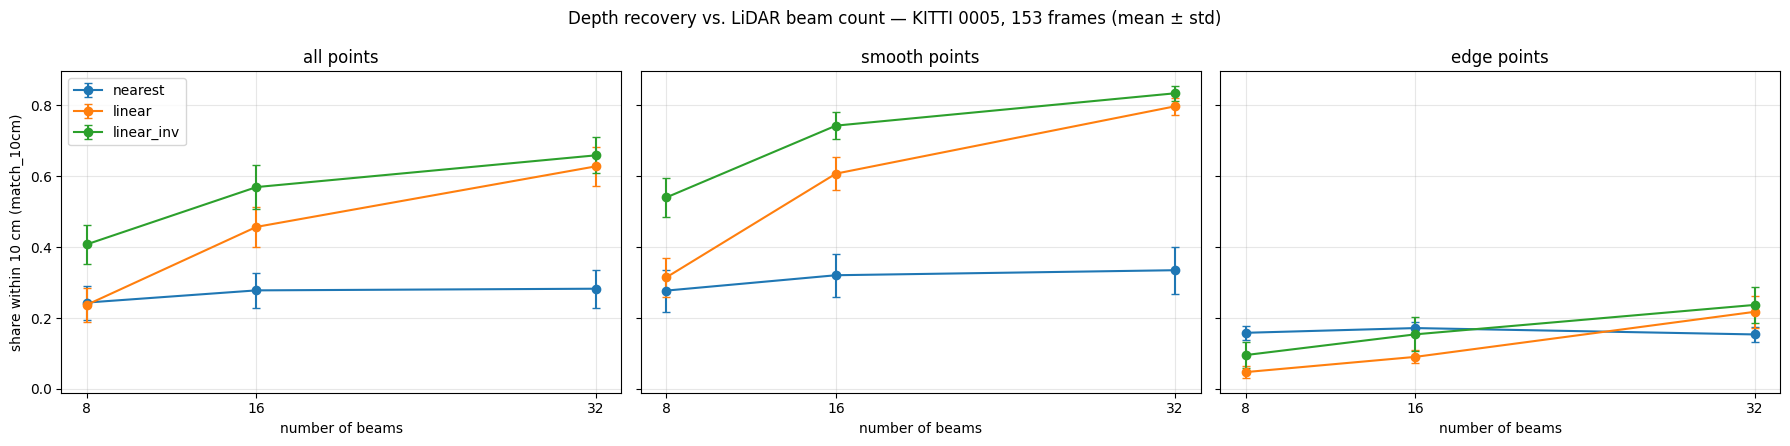

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, region in zip(axes, ["all", "smooth", "edge"]):
    for m in ["nearest", "linear", "linear_inv"]:
        g = df[(df.region == region) & (df.method == m)].groupby("beams")["match_10cm"]
        mean, std = g.mean(), g.std()
        ax.errorbar(mean.index, mean.values, yerr=std.values, marker="o", capsize=3, label=m)
    ax.set(title=f"{region} points", xlabel="number of beams", xticks=[8, 16, 32])
    ax.grid(alpha=.3)
axes[0].set_ylabel("share within 10 cm (match_10cm)"); axes[0].legend()
plt.suptitle(f"Depth recovery vs. LiDAR beam count — KITTI 0005, {len(VALID_FRAMES)} frames (mean ± std)")
plt.tight_layout(); plt.savefig("match10_vs_beams.png", dpi=150); plt.show()

## 7. Export figures/results + edge-definition sensitivity check

In [21]:
# === Export: saves all README figures + result tables, and checks edge-definition sensitivity ===
# (re-run after the benchmark cells; writes /content/BeamBudget-LiDAR and downloads a zip)
import os, shutil
from google.colab import files
OUT = "/content/BeamBudget-LiDAR"
os.makedirs(f"{OUT}/figures", exist_ok=True); os.makedirs(f"{OUT}/results", exist_ok=True)

plt.figure(figsize=(18, 6)); plt.imshow(img)
plt.scatter(u, v, c=z, s=1.5, cmap="jet_r", vmax=50)
plt.colorbar(label="depth [m]", fraction=0.015)
plt.title("KITTI 0005 frame 0 - LiDAR projected onto image_02"); plt.axis("off")
plt.savefig(f"{OUT}/figures/projection_frame0.png", dpi=120, bbox_inches="tight"); plt.close()

az0 = np.arctan2(pts[:, 1], pts[:, 0])
el0 = np.degrees(np.arctan2(pts[:, 2], np.linalg.norm(pts[:, :2], axis=1)))
seg0 = np.concatenate([[0], np.cumsum(np.diff(az0) < -np.pi)])
ring0 = assign_rings(pts)
fr = np.abs(np.degrees(az0)) < 45
std_seg = [np.std(el0[(seg0 == k) & fr]) for k in np.unique(seg0)]
std_ring = [np.std(el0[(ring0 == k) & fr]) for k in range(64)]
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].plot(std_seg, ".-", label=f"naive +-180 deg split ({len(std_seg)} segments)")
ax[0].plot(std_ring, ".-", label="cut-angle corrected (64 rings)")
ax[0].set(title="Elevation std per ring (camera FOV)", xlabel="ring / segment id", ylabel="deg"); ax[0].legend()
ax[1].plot([np.median(el0[ring0 == k]) for k in range(64)], ".-")
ax[1].set(title="Median elevation per ring", xlabel="ring id", ylabel="deg")
ax[2].bar(range(64), np.bincount(ring0)); ax[2].set(title="Points per ring", xlabel="ring id")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/figures/ring_validation.png", dpi=120); plt.close()

fig, axes = plt.subplots(4, 1, figsize=(16, 16))
for ax_, nk in zip(axes, [64, 32, 16, 8]):
    k_ = reduce_beams(ring_img, nk)
    ax_.imshow(img); ax_.scatter(u[k_], v[k_], c=z[k_], s=1.5, cmap="jet_r", vmax=50)
    ax_.set_title(f"{nk} beams - {k_.sum()} of {len(k_)} image points ({100*k_.mean():.0f}%)"); ax_.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/beam_reduction_frame0.png", dpi=100); plt.close()

keep16 = reduce_beams(ring_img, 16)
pred16 = interpolate_depth(u[keep16], v[keep16], z[keep16], u[~keep16], v[~keep16], "linear_inv")
plt.figure(figsize=(18, 6)); plt.imshow(img)
plt.scatter(u[~keep16], v[~keep16], c=np.abs(pred16 - z[~keep16]), s=2, cmap="magma", vmin=0, vmax=2)
plt.colorbar(label="|error| [m] (clipped at 2)", fraction=0.015)
plt.title("16 beams, linear_inv - absolute error at held-out points"); plt.axis("off")
plt.savefig(f"{OUT}/figures/error_map_16beams.png", dpi=120, bbox_inches="tight"); plt.close()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax_, region in zip(axes, ["all", "smooth", "edge"]):
    for m in ["nearest", "linear", "linear_inv"]:
        g = df[(df.region == region) & (df.method == m)].groupby("beams")["match_10cm"]
        ax_.errorbar(g.mean().index, g.mean().values, yerr=g.std().values, marker="o", capsize=3, label=m)
    ax_.set(title=f"{region} points", xlabel="number of beams", xticks=[8, 16, 32]); ax_.grid(alpha=.3)
axes[0].set_ylabel("share within 10 cm"); axes[0].legend()
plt.suptitle(f"Depth recovery vs. LiDAR beam count - KITTI 0005, {len(VALID_FRAMES)} frames (mean +- std)")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/match10_vs_beams.png", dpi=150); plt.close()

df.to_csv(f"{OUT}/results/results_all_frames.csv", index=False)
summary.to_csv(f"{OUT}/results/summary_by_region_beams_method.csv")

xy = np.column_stack([u, v])
dist, nbr = cKDTree(xy).query(xy, k=9)
jump = np.abs(z[nbr[:, 1:]] - z[:, None]) > 1.0
sens = []
for radius in [None, 3, 5, 10, 20]:
    e_r = jump.any(axis=1) if radius is None else (jump & (dist[:, 1:] <= radius)).any(axis=1)
    eg = e_r[~keep16]
    ms_ = depth_metrics(pred16[~eg], z[~keep16][~eg]); me_ = depth_metrics(pred16[eg], z[~keep16][eg])
    sens.append(dict(radius_px="none" if radius is None else radius, edge_share=e_r.mean(),
                     smooth_mae=ms_["mae"], smooth_match10=ms_["match_10cm"],
                     edge_mae=me_["mae"], edge_match10=me_["match_10cm"]))
sens = pd.DataFrame(sens).round(3)
sens.to_csv(f"{OUT}/results/edge_sensitivity_frame0.csv", index=False)
print(sens.to_string(index=False))

shutil.make_archive("/content/beambudget_export", "zip", OUT)
print("EXPORT_DONE", sorted(os.listdir(f"{OUT}/figures")), sorted(os.listdir(f"{OUT}/results")))
files.download("/content/beambudget_export.zip")


radius_px  edge_share  smooth_mae  smooth_match10  edge_mae  edge_match10
     none       0.258       0.248           0.683     5.316         0.092
        3       0.102       0.729           0.589     8.708         0.029
        5       0.216       0.364           0.657     5.742         0.086
       10       0.258       0.253           0.682     5.307         0.092
       20       0.258       0.248           0.683     5.316         0.092
EXPORT_DONE ['beam_reduction_frame0.png', 'error_map_16beams.png', 'match10_vs_beams.png', 'projection_frame0.png', 'ring_validation.png'] ['edge_sensitivity_frame0.csv', 'results_all_frames.csv', 'summary_by_region_beams_method.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>